In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

with open("../data/TinyStories-valid.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(len(text))
print(text[:500])

19432979
 Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every day."
After playing with the car, Kitty and Spot felt thirsty. They found a small pond with clear water. They drank the water and felt very happy. They played together all day and became best friends.
<|endoftext|>
Once upon a time, in a big forest, there lived a rhinoceros named Roxy. Roxy loved to climb. She climbed trees, rocks, and hills. One da


In [2]:
import sys
sys.path.append("..")

from myLLM.tokenizer import CharTokenizer

tok = CharTokenizer(text)
print(tok.vocab_size)
print(tok.encode("hello"))

98
[64, 61, 68, 68, 71]


In [3]:
import numpy as np

ids = np.array(tok.encode(text), dtype = np.int64)
print(ids.shape)
print(ids[:20])

(19432979,)
[ 1 49 72 71 76 14  1 49 72 71 76  1 75 57 79  1 76 64 61  1]


In [4]:
from myLLM.bigram import count_bigrams

V = tok.vocab_size
N = count_bigrams(ids, V)
print(N.sum(), len(ids) - 1) 

19432978 19432978


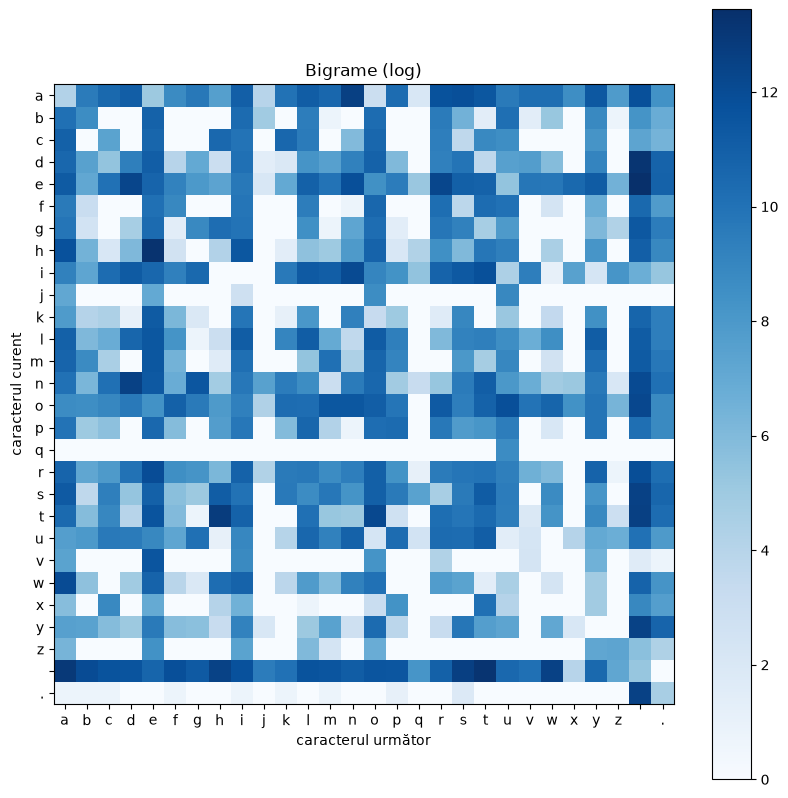

In [5]:
import matplotlib.pyplot as plt

alese = "abcdefghijklmnopqrstuvwxyz ."
idx = [tok.stoi[c] for c in alese]          # ID-urile caracterelor alese
sub = N[np.ix_(idx, idx)]                   # sub-matricea doar cu ele

plt.figure(figsize=(10, 10))
plt.imshow(np.log(sub + 1), cmap="Blues")
plt.xticks(range(len(alese)), list(alese))
plt.yticks(range(len(alese)), list(alese))
plt.xlabel("caracterul următor")
plt.ylabel("caracterul curent")
plt.title("Bigrame (log)")
plt.colorbar()
plt.show()

In [6]:
from myLLM.bigram import to_probs

P = to_probs(N)
print(P.shape)
print(np.allclose(P.sum(axis=1), 1))   # trebuie True

(98, 98)
True


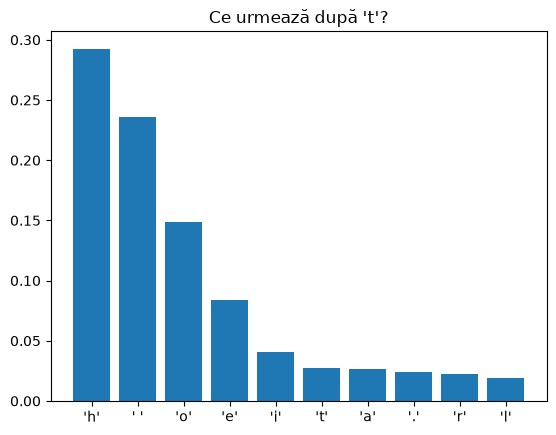

In [7]:
rand = P[tok.stoi["t"]]                  # rândul lui t: V probabilități
top = np.argsort(rand)[::-1][:10]        # ID-urile celor mai probabile 10

plt.bar([repr(tok.itos[i]) for i in top], rand[top])
plt.title("Ce urmează după 't'?")
plt.show()

In [11]:
from myLLM.bigram import generate

rng = np.random.default_rng(42)          # seed fix → același text la fiecare rulare
out = generate(P, tok.stoi["O"], 300, rng)
print(tok.decode(out))

Ondir whe hevere m the wis h arnte's an. hiratomar a thered Whedelind he. bald. ther Bend iend cke ayoray. he un'se tosarel h il? n we n was inthe d h to m s rmo wa matoitanay I'totoundema s waco apt dey a ack ire tis axiliry w mid hthoung Tis llthe, rsaigis Mo tcawalab, a ne. ito aikea fo t w try: p


In [13]:
from myLLM.bigram import nll_loss

n = int(0.9 * len(ids))
train_ids = ids[:n]
val_ids = ids[n:]

P_train = to_probs(count_bigrams(train_ids, V))

loss_train = nll_loss(P_train, train_ids)
loss_val = nll_loss(P_train, val_ids)

# reperul: un model care nu știe nimic și dă aceeași probabilitate fiecărui caracter
P_uniform = np.ones((V, V)) / V
loss_uniform = nll_loss(P_uniform, val_ids)

print("uniform:   ", loss_uniform, " ln(V) =", np.log(V))
print("train:     ", loss_train)
print("validare:  ", loss_val)
print("perplexitate:", np.exp(loss_val))

uniform:    4.584967478670573  ln(V) = 4.584967478670572
train:      2.2985096110174146
validare:   2.2958202235931173
perplexitate: 9.93257960817919
